<a href="https://colab.research.google.com/github/2025cspriyadharshinivf-cell/Branch/blob/main/Lab6(FeatureEng).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
data = pd.DataFrame({
    "Study_Hrs":[2,4,5,7,8,10],
    "Attendance_P":[50,60,65,75,85,95],
    "Assignment_Score":[35,45,55,65,80,95],
    "Final_Marks":[38,48,56,68,82,94]
})

display(data)

,Study_Hrs,Attendance_P,Assignment_Score,Final_Marks
0,2,50,35,38
1,4,60,45,48
2,5,65,55,56
3,7,75,65,68
4,8,85,80,82
5,10,95,95,94


In [ ]:
features =data[["Study_Hrs", "Attendance_P","Assignment_Score"]]

print("Minimum Values:")
print(features.min())
print("\nMaximum Values:")
print(features.max())

Minimum Values:
Study_Hrs            2
Attendance_P        50
Assignment_Score    35
dtype: int64

Maximum Values:
Study_Hrs           10
Attendance_P        95
Assignment_Score    95
dtype: int64


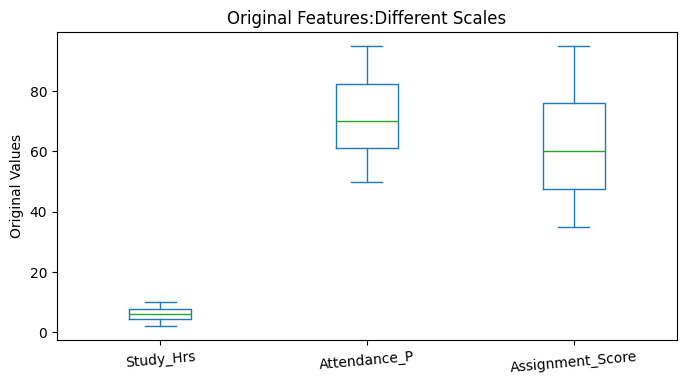

In [ ]:
features.plot(kind= "box", figsize=(8,4))
plt.title("Original Features:Different Scales")
plt.ylabel("Original Values")
plt.xticks(rotation=5)
plt.show()

In [ ]:
normalizer = MinMaxScaler()
normalized_array = normalizer.fit_transform(features)

normalized_df = pd.DataFrame(
    normalized_array,
    columns=features.columns,
    index=features.index
    )

display(normalized_df.round(3))

,Study_Hrs,Attendance_P,Assignment_Score
0,0.000,0.000,0.000
1,0.250,0.222,0.167
2,0.375,0.333,0.333
3,0.625,0.556,0.500
4,0.750,0.778,0.750
5,1.000,1.000,1.000


In [ ]:
print("Means after normalization:")
print(normalized_df.mean().round(6))

print("\nNormal Deviations after normalization:")
print(normalized_df.std(ddfo=0).round(6))

Means after normalization:
Study_Hrs           0.500000
Attendance_P        0.481481
Assignment_Score    0.458333
dtype: float64

Normal Deviations after normalization:


TypeError: std() got an unexpected keyword argument 'ddfo'

In [ ]:
print("Minimum after normalization:")
print(normalized_df.min())
print("\nMaximum after normalization:")
print(normalized_df.max())

Minimum after normalization:
Study_Hrs           0.0
Attendance_P        0.0
Assignment_Score    0.0
dtype: float64

Maximum after normalization:
Study_Hrs           1.0
Attendance_P        1.0
Assignment_Score    1.0
dtype: float64


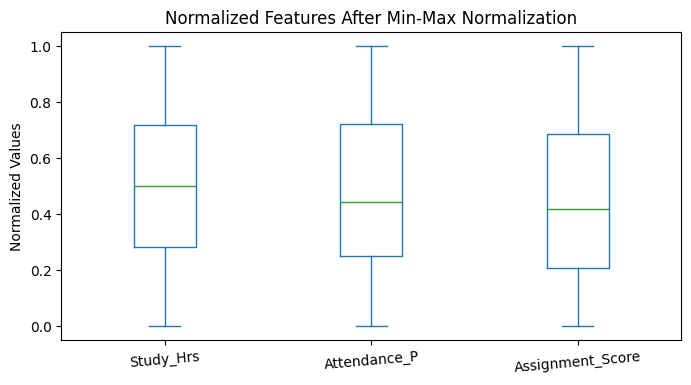

In [ ]:
normalized_df.plot(kind= "box", figsize=(8,4))
plt.title("Normalized Features After Min-Max Normalization")
plt.ylabel("Normalized Values")
plt.xticks(rotation=5)
plt.show()

In [ ]:
standardizer = MinMaxScaler()
standardized_array = normalizer.fit_transform(features)

standardized_df = pd.DataFrame(
    standardized_array,
    columns=features.columns,
    index=features.index
    )

display(standardized_df.round(3))

,Study_Hrs,Attendance_P,Assignment_Score
0,0.000,0.000,0.000
1,0.250,0.222,0.167
2,0.375,0.333,0.333
3,0.625,0.556,0.500
4,0.750,0.778,0.750
5,1.000,1.000,1.000


In [ ]:
print("Means after standardization:")
print(standardized_df.round(6))
print("\nStandard deviations after standardization:")
print(standardized_df.std(ddof=0).round(6))

Means after standardization:
   Study_Hrs  Attendance_P  Assignment_Score
0      0.000      0.000000          0.000000
1      0.250      0.222222          0.166667
2      0.375      0.333333          0.333333
3      0.625      0.555556          0.500000
4      0.750      0.777778          0.750000
5      1.000      1.000000          1.000000

Standard deviations after standardization:
Study_Hrs           0.330719
Attendance_P        0.337423
Assignment_Score    0.339355
dtype: float64


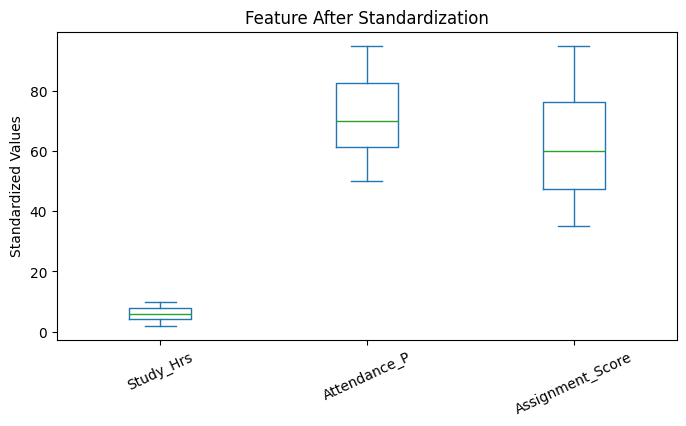

In [ ]:
features.plot(kind= "box", figsize=(8,4))
plt.title("Feature After Standardization")
plt.ylabel("Standardized Values")
plt.xticks(rotation=25)
plt.show()

In [ ]:
scaled_features = StandardScaler().fit_transform(features)

pca = PCA(n_components=2)

pca_array = pca.fit_transform(scaled_features)

pca_df = pd.DataFrame(
    pca_array,
    columns=["PC1", "PC2"],
    index = features.index
)

display(pca_df)

,PC1,PC2
0,-2.476452,-0.114569
1,-1.376242,0.068945
2,-0.684425,-0.001284
3,0.415785,0.182231
4,1.439706,-0.078426
5,2.681628,-0.056897


In [ ]:
 variance_ratios = pca.explained_variance_ratio_

for component, ratio in zip(["PC1", "PC2"], variance_ratios):
  print(f"{component} explains {ratio:.2%} of the variance")

total_retained = variance_ratios.sum()
print(f"Total variance retained by 2 components: {total_retained:.2%}")

PC1 explains 99.62% of the variance
PC2 explains 0.34% of the variance
Total variance retained by 2 components: 99.96%


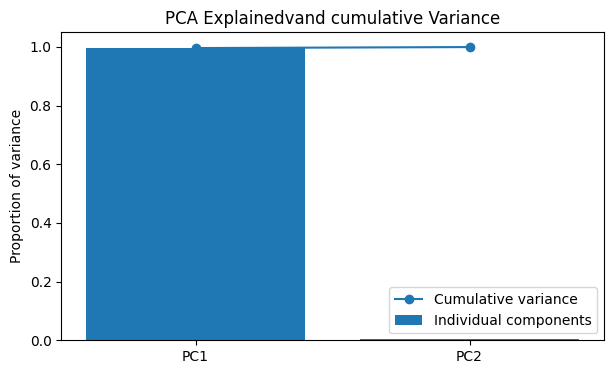

In [ ]:
components_names = ["PC1", "PC2"]
cumulative_variance = variance_ratios.cumsum()

plt.figure(figsize=(7,4))
plt.bar(components_names, variance_ratios)
plt.plot(components_names, cumulative_variance, marker="o")

plt.ylim(0, 1.05)
plt.ylabel("Proportion of variance")
plt.title("PCA Explainedvand cumulative Variance")
plt.legend(["Cumulative variance","Individual components"])
plt.show()